# Анализ утилити одного игрока: что улучшить (Cache, Premier/MM)

## 1. Введение и цель анализа

Это proof-of-concept персонального отчёта для пользователя SCOPE.GG: берём **одного игрока** из датасета
`data/grenades_by_match_0726.list` (10 000 матчей на Cache) и разбираем, как он использует гранаты — смоки, флешки, HE и молотовы.

Каждую метрику игрока сравниваем с тремя ориентирами:
- **команда** — его тиммейты в тех же матчах;
- **датасет** — все броски всех игроков;
- **его тир** — игроки с похожим `PremierRatingNew` (раздел 11).

В конце (раздел 12) — конкретные рекомендации с цифрами из этого ноутбука и ссылкой на инструмент SCOPE.GG,
который закрывает каждую проблему (по `docs/scope_gg_products_research.md`).

Загрузка и плоские таблицы — те же, что в `notebooks/eda.ipynb` (функция `flatten()` и кэш `data/processed/*.parquet`).

## Содержание

Коротко: персональный разбор утилити одного игрока против команды, датасета и своего тира.

1. **Введение и цель анализа** — зачем отчёт и с чем сравниваем метрики игрока.
2. **Ограничения датасета** — каких данных нет и какие выводы поэтому невозможны.
3. **Загрузка и подготовка данных** — плоские таблицы, производные признаки, выбор игрока.
4. **Обзор активности игрока по утилити** — сколько и каких гранат игрок бросает за матч.
5. **Микс гранат** — доли типов гранат у игрока против команды и датасета.
6. **Анализ флешбангов** — ослепление врагов и тиммейтов, длительность флешей.
7. **Анализ HE-гранат** — урон от HE и доля бесполезных бросков.
8. **Анализ молотовов (Fire)** — урон огнём и эффективность молотовов.
9. **Консистентность лайнапов (смоки)** — насколько стабильно игрок повторяет точки броска смоков.
10. **Тайминг бросков по раунду** — в какие моменты раунда игрок тратит утилити.
11. **Связь метрик утилити с PremierRatingNew** — сравнение игрока с его рейтинговым тиром.
12. **Выводы для игрока** — конкретные рекомендации с цифрами и инструментами SCOPE.GG.

## 2. Ограничения датасета

Прежде чем смотреть на цифры, фиксируем, **что из этих данных сказать нельзя**. В датасете есть только события гранат, поэтому:

- **Нет данных о стрельбе и аиме.** Ни выстрелов, ни попаданий, ни хедшотов, ни убийств с оружия. Про аим этот отчёт ничего не говорит.
- **Нет движения и позиций игрока вне моментов броска.** Мы знаем, где игрок стоял, только когда он бросал гранату
  (и где стояла жертва в момент ослепления/урона). Про общее позиционирование и мувмент выводов нет.
- **Нет экономики раунда:** денег, закупа, оружия, того, сколько гранат игрок купил. «Мало гранат» может значить «не было денег».
- **Нет смертей не от гранат и результата раунда/матча.** Влияние утилити на победу в раунде не измерить.
- **Нет начала раунда (тика окончания freeze time).** Время «от начала раунда» в разделе 10 считаем от первой гранаты в раунде
  (любого игрока) — это прокси.
- **Урон HE и огня по своим не записан** (`DamagedPlayers` содержит только врагов, см. EDA 1.2). Поэтому «тимдамаг» оцениваем только по флешкам.
- **У смоков нет исхода**: что смок перекрыл и сколько стоял — неизвестно. Остаётся только точка приземления.
- **Маленькая выборка на одного игрока.** В датасете 10 000 случайных матчей, и один игрок встречается максимум в ~10 из них.
  Значит, у выбранного игрока несколько сотен бросков, а по отдельным типам — десятки. Все выводы ниже — ориентир, а не диагноз.
- `PremierRatingNew` заполнен примерно у четверти игроков-матчей; сравнение «с тиром» сделано только по ним.
- Нет callouts и радара: позиции — сырые координаты, названия точек мы не подставляем.

Итого: **это анализ только использования гранат**. Аим, мувмент, экономику и общую игру он не покрывает.

## 3. Загрузка и подготовка данных

Те же константы и стиль, что в `eda.ipynb`.

In [1]:
import gc
import os
import pickle
import time

import bson  # noqa: F401  -- нужен, чтобы pickle смог импортировать bson.int64.Int64 / bson.objectid.ObjectId
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 90
plt.rcParams['figure.figsize'] = (10, 4.5)
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')

DATA_PATH = '../data/grenades_by_match_0726.list'
CACHE_DIR = '../data/processed'
TICKRATE = 64  # проверено в eda.ipynb: фитиль HE/флешки = 104 тика = 1.625 с
GT_ORDER = ['smoke', 'flash', 'he', 'molotov']
GT_COLORS = {'smoke': '#7f7f7f', 'flash': '#e5ae38', 'he': '#2ca02c', 'molotov': '#d62728'}
TEAM_NAME = {2: 'T', 3: 'CT'}
TEAM_COLORS = {'T': '#d9a441', 'CT': '#4a7ab5'}
# цвета для сравнения «игрок / его команда / весь датасет»
CMP_COLORS = {'игрок': '#c44e52', 'команда': '#4c72b0', 'датасет': '#8c8c8c'}

### 3.1 Плоские таблицы

Функция `flatten()` скопирована из `eda.ipynb` без изменений. Если `eda.ipynb` уже запускался, она не вызывается:
таблицы читаются из кэша `data/processed/*.parquet`.

In [2]:
GTYPES = {'Smokes': 'smoke', 'Flashbangs': 'flash', 'HEs': 'he', 'Fires': 'molotov'}


def flatten(data):
    """Раскладывает матчи на 4 таблицы: throws, damage (HE + огонь), flashed, players. Копия из eda.ipynb."""
    T = {k: [] for k in [
        'match_id', 'grenade_type', 'round', 'round_demo', 'thrower_id', 'team',
        'tp_x', 'tp_y', 'tp_z', 'vel_x', 'vel_y', 'vel_z', 'view_x', 'view_y',
        'is_crouching', 'is_airborne', 'spv_x', 'spv_y', 'spv_z',
        'start_tick', 'end_tick', 'start_frame', 'end_frame',
        'from_x', 'from_y', 'from_z', 'to_x', 'to_y', 'to_z', 'hull_n_vertices']}
    D = {k: [] for k in ['throw_idx', 'victim_id', 'victim_team', 'n_hits', 'health_dmg',
                         'armor_dmg', 'killed', 'v_x', 'v_y', 'v_z', 'first_tick']}
    F = {k: [] for k in ['throw_idx', 'victim_id', 'victim_team', 'flash_duration', 'flash_added',
                         'flash_existing', 'v_x', 'v_y', 'v_z', 'va_x', 'va_y',
                         'killed', 'killed_by', 'killed_remaining_flash']}
    P = {k: [] for k in ['match_id', 'player_id', 'rating']}
    idx = 0
    for m in data:
        mid = int(m['MatchID'])
        for p in m['Players']:
            P['match_id'].append(mid)
            P['player_id'].append(int(p['StaticInfo']['PlayerID']))
            P['rating'].append(p.get('PremierRatingNew', np.nan))
        for key, gt in GTYPES.items():
            for g in m.get(key) or []:
                gi = g['GeneralInfo']
                tp = gi['ThrowPoint']
                pos, vel, spv = tp['Position'], tp['Velocity'], gi['StartProperVelocity']
                pf, pt = gi['PosFrom'], gi['PosTo']
                T['match_id'].append(mid); T['grenade_type'].append(gt)
                T['round'].append(gi['RoundIndexMatch']); T['round_demo'].append(gi['RoundIndexDemo'])
                T['thrower_id'].append(gi['ThrowerID']); T['team'].append(gi['Team'])
                T['tp_x'].append(pos['X']); T['tp_y'].append(pos['Y']); T['tp_z'].append(pos['Z'])
                T['vel_x'].append(vel['X']); T['vel_y'].append(vel['Y']); T['vel_z'].append(vel['Z'])
                T['view_x'].append(tp['ViewX']); T['view_y'].append(tp['ViewY'])
                T['is_crouching'].append(tp['IsCrouching']); T['is_airborne'].append(tp['IsAirborne'])
                T['spv_x'].append(spv['X']); T['spv_y'].append(spv['Y']); T['spv_z'].append(spv['Z'])
                T['start_tick'].append(gi['StartTick']); T['end_tick'].append(gi['EndTick'])
                T['start_frame'].append(gi['StartFrame']); T['end_frame'].append(gi['EndFrame'])
                T['from_x'].append(pf['X']); T['from_y'].append(pf['Y']); T['from_z'].append(pf['Z'])
                T['to_x'].append(pt['X']); T['to_y'].append(pt['Y']); T['to_z'].append(pt['Z'])
                hull = ((g.get('FinalInfernoInfo') or {}).get('ConvexHull3D') or {}).get('Vertices')
                T['hull_n_vertices'].append(len(hull or []) if gt == 'molotov' else np.nan)

                for v in g.get('DamagedPlayers') or []:
                    dm = v.get('Damage') or []
                    if not dm:
                        continue
                    D['throw_idx'].append(idx)
                    D['victim_id'].append(v['PlayerID']); D['victim_team'].append(v['Team'])
                    D['n_hits'].append(len(dm))
                    D['health_dmg'].append(sum(e['HealthDamage'] for e in dm))
                    D['armor_dmg'].append(sum(e['ArmorDamage'] for e in dm))
                    D['killed'].append(any(e.get('WasKilled', False) for e in dm))
                    p0 = dm[0]['Position']
                    D['v_x'].append(p0['X']); D['v_y'].append(p0['Y']); D['v_z'].append(p0['Z'])
                    D['first_tick'].append(dm[0]['TickNumber'])

                for v in g.get('FlashedPlayers') or []:
                    vp, va = v['Position'], v['ViewAngle']
                    F['throw_idx'].append(idx)
                    F['victim_id'].append(v['PlayerID']); F['victim_team'].append(v['Team'])
                    F['flash_duration'].append(v['FlashDuration'])
                    F['flash_added'].append(v['FlashDurationAdded'])
                    F['flash_existing'].append(v['ExistingFlashDuration'])
                    F['v_x'].append(vp['X']); F['v_y'].append(vp['Y']); F['v_z'].append(vp['Z'])
                    F['va_x'].append(va['X']); F['va_y'].append(va['Y'])
                    wk = v.get('WasKilled')  # у флешек это dict {By, From, TickNumber, RemainingFlashDuration, OpenKill?}
                    F['killed'].append(wk is not None)
                    F['killed_by'].append(wk['By'] if wk else -1)
                    F['killed_remaining_flash'].append(wk['RemainingFlashDuration'] if wk else np.nan)
                idx += 1

    throws = pd.DataFrame(T)
    for c in throws.columns:
        if throws[c].dtype == 'float64':
            throws[c] = throws[c].astype('float32')
    for c in ['round', 'round_demo', 'team']:
        throws[c] = throws[c].astype('int16')
    for c in ['start_tick', 'end_tick', 'start_frame', 'end_frame']:
        throws[c] = throws[c].astype('int32')
    throws['thrower_id'] = throws['thrower_id'].astype('int64')
    damage = pd.DataFrame(D).astype({'victim_id': 'int64', 'victim_team': 'int16'})
    flashed = pd.DataFrame(F).astype({'victim_id': 'int64', 'victim_team': 'int16'})
    players = pd.DataFrame(P)
    return throws, damage, flashed, players


cache_files = {n: os.path.join(CACHE_DIR, f'{n}.parquet') for n in ['throws', 'damage', 'flashed', 'players']}
if all(os.path.exists(f) for f in cache_files.values()):
    print('Читаем кэш parquet:', CACHE_DIR)
    throws, damage, flashed, players = (pd.read_parquet(cache_files[n]) for n in ['throws', 'damage', 'flashed', 'players'])
else:
    print('Кэша нет, читаем pickle (1–2 минуты, ~4 ГБ RAM)')
    t0 = time.time()
    with open(DATA_PATH, 'rb') as fh:
        data = pickle.load(fh)
    throws, damage, flashed, players = flatten(data)
    print(f'load + flatten: {time.time() - t0:.0f} c')
    del data
    gc.collect()
    os.makedirs(CACHE_DIR, exist_ok=True)
    for n, df in zip(['throws', 'damage', 'flashed', 'players'], [throws, damage, flashed, players]):
        df.to_parquet(cache_files[n], index=False)

for name, df in [('throws', throws), ('damage', damage), ('flashed', flashed), ('players', players)]:
    print(f'{name:8s} {df.shape[0]:>10,} строк × {df.shape[1]:>2} колонок')

Читаем кэш parquet: ../data/processed


throws    2,385,417 строк × 30 колонок
damage      344,524 строк × 11 колонок
flashed   1,001,026 строк × 14 колонок
players      99,921 строк ×  3 колонок


### 3.2 Производные признаки

Как в `eda.ipynb` (раздел 1.1), сводим исходы на уровень одного броска. `throw_idx` в `damage`/`flashed` — это номер строки в `throws`,
поэтому джойны делаем до любой фильтрации. Дополнительно к EDA считаем:
- число ослеплённых **врагов / тиммейтов / себя** на флешку;
- `flash_kills` — враг убит, пока был ослеплён этой флешкой; `flash_kills_own` — убил сам бросивший;
- `t_in_round` — секунды от первой гранаты раунда (любого игрока) до этого броска (прокси начала раунда, см. раздел 2).

In [3]:
throws['side'] = throws['team'].map(TEAM_NAME)

meta = throws[['team', 'thrower_id', 'grenade_type', 'match_id', 'round']]
damage = damage.join(meta, on='throw_idx')
flashed = flashed.join(meta, on='throw_idx')
for df in (damage, flashed):
    df['rel'] = np.select([df['victim_id'] == df['thrower_id'], df['victim_team'] == df['team']],
                          ['self', 'team'], 'enemy')

# HE / огонь: DamagedPlayers содержит только врагов
en = damage[damage['rel'] == 'enemy'].groupby('throw_idx').agg(
    enemy_dmg=('health_dmg', 'sum'), enemy_armor_dmg=('armor_dmg', 'sum'),
    n_enemies_hit=('victim_id', 'size'), enemy_kills=('killed', 'sum'))
# флешки: сколько ослеплено врагов / своих / себя
fl_n = flashed.groupby(['throw_idx', 'rel']).size().unstack(fill_value=0)
fl_n = fl_n.reindex(columns=['enemy', 'team', 'self'], fill_value=0).add_prefix('n_flashed_')
fl_en = (flashed[flashed['rel'] == 'enemy']
         .assign(own_kill=lambda d: d['killed'] & (d['killed_by'] == d['thrower_id']))
         .groupby('throw_idx').agg(enemy_blind_s=('flash_duration', 'sum'),
                                   flash_kills=('killed', 'sum'), flash_kills_own=('own_kill', 'sum')))
throws = throws.join(en).join(fl_n).join(fl_en)

dmg_cols = ['enemy_dmg', 'enemy_armor_dmg', 'n_enemies_hit', 'enemy_kills']
fl_cols = ['n_flashed_enemy', 'n_flashed_team', 'n_flashed_self', 'enemy_blind_s', 'flash_kills', 'flash_kills_own']
is_dmg = throws['grenade_type'].isin(['he', 'molotov'])
is_fl = throws['grenade_type'] == 'flash'
for c in dmg_cols:
    throws[c] = throws[c].where(~is_dmg, throws[c].fillna(0)).astype('float32')
for c in fl_cols:
    throws[c] = throws[c].where(~is_fl, throws[c].fillna(0)).astype('float32')
throws['n_flashed_own'] = throws['n_flashed_team'] + throws['n_flashed_self']

round_t0 = throws.groupby(['match_id', 'round'])['start_tick'].transform('min')
throws['t_in_round'] = (throws['start_tick'] - round_t0) / TICKRATE

# число сыгранных раундов в матче (макс. раунд с гранатой + 1, как в EDA)
rounds_in_match = throws.groupby('match_id')['round'].max() + 1

summary_cols = ['enemy_dmg', 'n_flashed_enemy', 'n_flashed_own', 't_in_round']
preview = throws.groupby('grenade_type')[summary_cols].mean()
preview.insert(0, 'n_throws', throws.groupby('grenade_type').size())
preview = preview.reindex(GT_ORDER)
preview.style.format('{:.2f}', subset=summary_cols, na_rep='не определено для типа').format('{:d}', subset=['n_throws'])

,n_throws,enemy_dmg,n_flashed_enemy,n_flashed_own,t_in_round
grenade_type,,,,,
smoke,729947,не определено для типа,не определено для типа,не определено для типа,15.15
flash,643914,не определено для типа,0.75,0.80,18.96
he,565392,8.73,не определено для типа,не определено для типа,22.54
molotov,446164,2.43,не определено для типа,не определено для типа,23.82


### 3.3 Выбор игрока

Нам нужен игрок с максимальной выборкой. Смотрим, сколько матчей и бросков у каждого `ThrowerID`.

In [4]:
per_player = throws.groupby('thrower_id').agg(throws=('match_id', 'size'), matches=('match_id', 'nunique'))
rated_matches = players.dropna(subset=['rating']).groupby('player_id')['match_id'].nunique()
per_player['rated_matches'] = rated_matches.reindex(per_player.index).fillna(0).astype(int)

print(f'Игроков, бросавших гранаты: {len(per_player):,}')
print('Матчей на игрока (сколько игроков):', per_player['matches'].value_counts().sort_index().to_dict())
print('Бросков на игрока, квантили:', per_player['throws'].quantile([0.5, 0.9, 0.99, 1.0]).to_dict())

MIN_MATCHES = 8
cand = per_player[per_player['matches'] >= MIN_MATCHES].sort_values('throws', ascending=False)
PLAYER_ID = int(cand.index[0])
print(f'\nВыбран игрок {PLAYER_ID}: максимум бросков среди игроков с ≥{MIN_MATCHES} матчами')
cand.head(10)

Игроков, бросавших гранаты: 89,052
Матчей на игрока (сколько игроков): {1: 82295, 2: 5362, 3: 963, 4: 270, 5: 102, 6: 33, 7: 17, 8: 3, 9: 6, 10: 1}
Бросков на игрока, квантили: {0.5: 23.0, 0.9: 49.0, 0.99: 96.0, 1.0: 390.0}

Выбран игрок 441472604: максимум бросков среди игроков с ≥8 матчами


,throws,matches,rated_matches
thrower_id,,,
441472604,310,9,5
1543392117,301,8,8
1426773476,296,9,5
1112652773,271,9,5
152517239,256,9,4
12262308,230,9,6
1179074578,203,10,4
140063803,171,9,4
103347565,126,8,8


Подавляющее большинство игроков встречаются в датасете один раз. Поэтому критерий выбора такой: среди игроков,
у которых **≥ 8 матчей** (верх распределения по матчам), берём того, у кого **больше всего бросков**.
Больше матчей — меньше зависимость от одной игры, больше бросков — устойчивее доли по типам гранат.

In [5]:
me = throws[throws['thrower_id'] == PLAYER_ID].copy()
my_rating = (players[players['player_id'] == PLAYER_ID].drop_duplicates('match_id')
             .set_index('match_id')['rating'])

by_match = me.groupby(['match_id', 'grenade_type']).size().unstack(fill_value=0).reindex(columns=GT_ORDER, fill_value=0)
by_match['всего'] = by_match.sum(axis=1)
by_match['раундов'] = rounds_in_match.reindex(by_match.index)
by_match['гранат/раунд'] = by_match['всего'] / by_match['раундов']
by_match['рейтинг'] = my_rating.reindex(by_match.index)
by_match.index = [f'матч {i + 1}' for i in range(len(by_match))]

MY_RATING = my_rating.mean()
print(f'Игрок {PLAYER_ID}: {len(me)} бросков в {me["match_id"].nunique()} матчах, '
      f'рейтинг известен в {my_rating.notna().sum()} матчах, средний {MY_RATING:,.0f}')
by_match

Игрок 441472604: 310 бросков в 9 матчах, рейтинг известен в 5 матчах, средний 16,568


grenade_type,smoke,flash,he,molotov,всего,раундов,гранат/раунд,рейтинг
матч 1,3,2,0,0,5,5,1.000,NaN
матч 2,7,7,10,10,34,20,1.700,NaN
матч 3,12,16,9,11,48,21,2.286,NaN
матч 4,5,8,2,2,17,17,1.000,NaN
матч 5,12,17,8,8,45,22,2.045,"16,515.000"
матч 6,10,10,8,6,34,16,2.125,"16,856.000"
матч 7,8,10,10,6,34,23,1.478,"16,553.000"
матч 8,12,14,7,6,39,24,1.625,"16,289.000"
матч 9,15,21,13,5,54,24,2.250,"16,626.000"


## 4. Обзор активности игрока по утилити

Сколько гранат и каких игрок бросает за матч. Для сравнения нормируем на число раундов: «гранат за раунд» у игрока
против среднего игрока датасета (все пары «игрок–матч» из `Players`, включая тех, кто не бросил ничего).

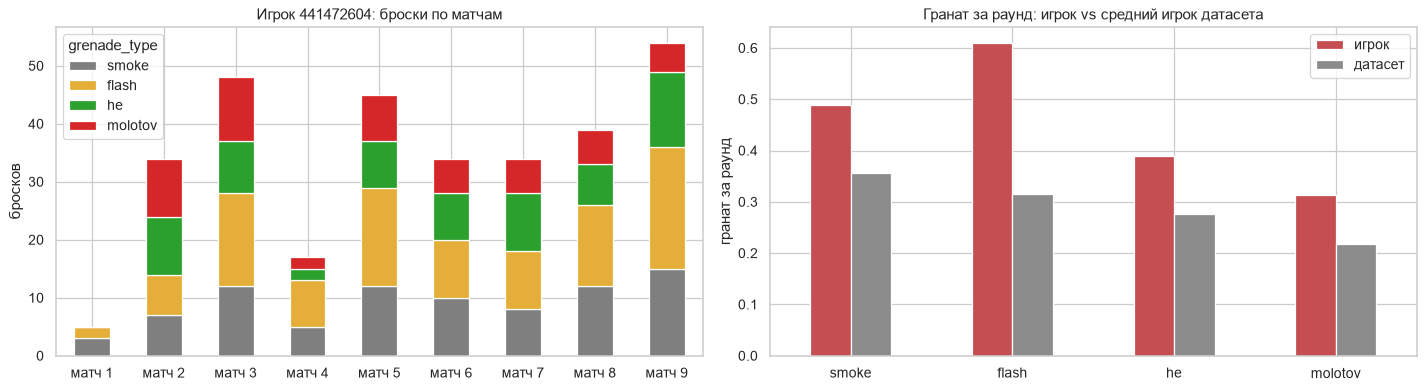

,игрок,датасет,игрок / датасет
smoke,0.488,0.357,1.369
flash,0.610,0.315,1.940
he,0.390,0.276,1.410
molotov,0.314,0.218,1.440
всего,1.802,1.165,1.546


In [6]:
# пары игрок–матч из Players + число бросков каждого типа
pm = throws.groupby(['match_id', 'thrower_id', 'grenade_type']).size().unstack(fill_value=0)
pm = (players.drop_duplicates(['match_id', 'player_id']).rename(columns={'player_id': 'thrower_id'})
      .set_index(['match_id', 'thrower_id']).join(pm).fillna({g: 0 for g in GT_ORDER}))
pm['rounds'] = rounds_in_match.reindex(pm.index.get_level_values('match_id')).values

rate = pd.DataFrame({
    'игрок': me['grenade_type'].value_counts().reindex(GT_ORDER) / by_match['раундов'].sum(),
    'датасет': pm[GT_ORDER].sum() / pm['rounds'].sum(),
})
rate.loc['всего'] = rate.sum()

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
by_match[GT_ORDER].plot(kind='bar', stacked=True, color=[GT_COLORS[g] for g in GT_ORDER], ax=axes[0])
axes[0].set_title(f'Игрок {PLAYER_ID}: броски по матчам'); axes[0].set_ylabel('бросков'); axes[0].tick_params(axis='x', rotation=0)
rate.loc[GT_ORDER].plot(kind='bar', color=[CMP_COLORS['игрок'], CMP_COLORS['датасет']], ax=axes[1])
axes[1].set_title('Гранат за раунд: игрок vs средний игрок датасета'); axes[1].set_ylabel('гранат за раунд'); axes[1].tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()
rate.assign(**{'игрок / датасет': rate['игрок'] / rate['датасет']})

Игрок сыграл 9 матчей (у первого всего 5 раундов с гранатами — похоже, матч оборван или игрок зашёл поздно) и бросает
**1.80 гранаты за раунд — в 1.5 раза больше среднего игрока датасета** (1.17). Сильнее всего перевес по флешкам: 0.61 за раунд
против 0.32 (×1.9). То есть утилити он покупает и использует активно, вопрос — в качестве бросков.

## 5. Микс гранат: игрок vs команда vs датасет

Доля каждого типа в бросках игрока. «Команда» — тиммейты игрока в тех же матчах: игроки, которые бросали гранаты
за ту же сторону в те же раунды, что и он (`Team` — это сторона, поэтому сравниваем по раунду).

Тиммейтов (игрок–матч): 35, их бросков: 825


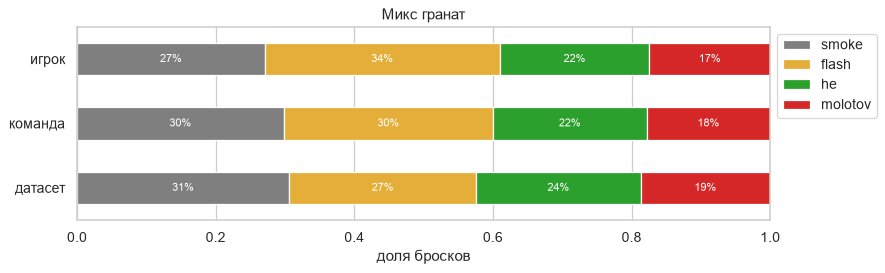

In [7]:
my_rounds = me[['match_id', 'round', 'team']].drop_duplicates()
mates = (throws.merge(my_rounds, on=['match_id', 'round', 'team'])[['match_id', 'thrower_id']]
         .drop_duplicates().query('thrower_id != @PLAYER_ID'))
team_throws = throws.merge(mates, on=['match_id', 'thrower_id'])
print(f'Тиммейтов (игрок–матч): {len(mates)}, их бросков: {len(team_throws):,}')

mix = pd.DataFrame({
    'игрок': me['grenade_type'].value_counts(normalize=True),
    'команда': team_throws['grenade_type'].value_counts(normalize=True),
    'датасет': throws['grenade_type'].value_counts(normalize=True),
}).reindex(GT_ORDER).T

fig, ax = plt.subplots(figsize=(10, 3.2))
mix.plot(kind='barh', stacked=True, color=[GT_COLORS[g] for g in GT_ORDER], ax=ax)
for i, (_, row) in enumerate(mix.iterrows()):
    left = 0
    for g in GT_ORDER:
        ax.text(left + row[g] / 2, i, f'{row[g]:.0%}', ha='center', va='center', fontsize=9, color='white')
        left += row[g]
ax.invert_yaxis(); ax.set_xlim(0, 1); ax.set_xlabel('доля бросков'); ax.set_title('Микс гранат')
ax.legend(bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.show()

mix_side = pd.concat({
    'игрок': pd.crosstab(me['side'], me['grenade_type'], normalize='index'),
    'датасет': pd.crosstab(throws['side'], throws['grenade_type'], normalize='index'),
}).reindex(columns=GT_ORDER)
mix_side.style.format('{:.1%}')

Микс у игрока смещён во **флешки**: 34% бросков против 30% у его тиммейтов и 27% по датасету; смоков, наоборот, меньше (27% против 30–31%).
На стороне T флешки — 39% его бросков (по датасету 33%). Это похоже на роль игрока, который заводит команду на плент,
поэтому качество флешек для него особенно важно (раздел 6).

## 6. Анализ флешбангов

Метрики на одну флешку:
- **враги / тиммейты / сам** — сколько игроков каждой группы попало в `FlashedPlayers` (любая длительность);
- **team-flash ratio** — сколько своих (тиммейты + сам) ослеплено на одного ослеплённого врага. Меньше — лучше;
- **пустая флешка** — не ослепила ни одного врага (отдельно — не ослепила вообще никого);
- **flash-kill** — ослеплённый этой флешкой враг убит, пока ещё слеп (кем угодно / самим бросившим).

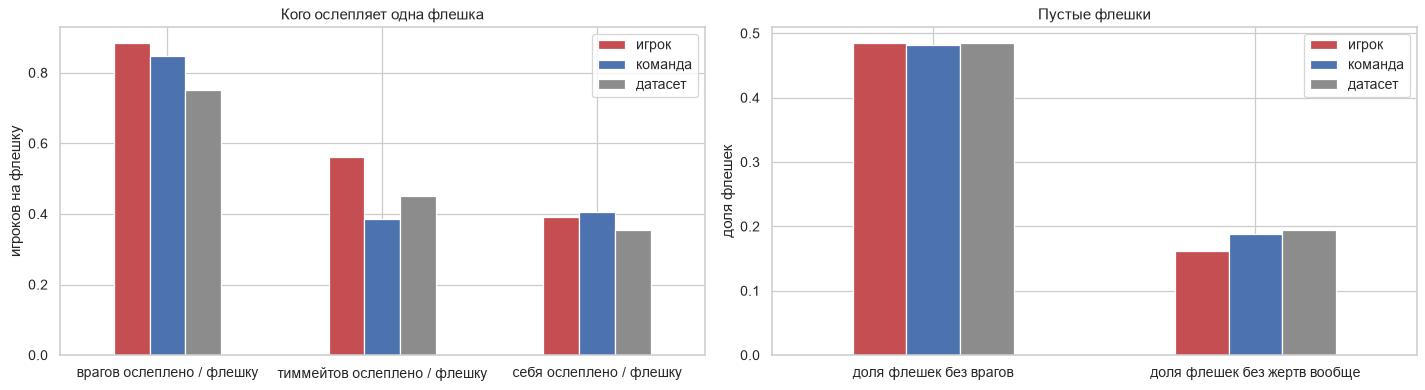

,игрок,команда,датасет
флешек,105.000,249.000,"643,914.000"
врагов ослеплено / флешку,0.886,0.847,0.750
тиммейтов ослеплено / флешку,0.562,0.386,0.451
себя ослеплено / флешку,0.390,0.406,0.353
team-flash ratio (свои / враги),1.075,0.934,1.072
доля флешек без врагов,0.486,0.482,0.484
доля флешек без жертв вообще,0.162,0.189,0.194
слепых сек врагов / флешку,2.542,2.304,1.949
flash-kill на 100 флешек,1.905,2.410,4.827
…из них убил сам,0.000,2.008,2.367


In [8]:
def flash_metrics(f):
    return pd.Series({
        'флешек': len(f),
        'врагов ослеплено / флешку': f['n_flashed_enemy'].mean(),
        'тиммейтов ослеплено / флешку': f['n_flashed_team'].mean(),
        'себя ослеплено / флешку': f['n_flashed_self'].mean(),
        'team-flash ratio (свои / враги)': f['n_flashed_own'].sum() / f['n_flashed_enemy'].sum(),
        'доля флешек без врагов': (f['n_flashed_enemy'] == 0).mean(),
        'доля флешек без жертв вообще': ((f['n_flashed_enemy'] + f['n_flashed_own']) == 0).mean(),
        'слепых сек врагов / флешку': f['enemy_blind_s'].mean(),
        'flash-kill на 100 флешек': 100 * f['flash_kills'].mean(),
        '…из них убил сам': 100 * f['flash_kills_own'].mean(),
    })


fl_tab = pd.DataFrame({
    'игрок': flash_metrics(me[me['grenade_type'] == 'flash']),
    'команда': flash_metrics(team_throws[team_throws['grenade_type'] == 'flash']),
    'датасет': flash_metrics(throws[throws['grenade_type'] == 'flash']),
})

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
fl_tab.loc[['врагов ослеплено / флешку', 'тиммейтов ослеплено / флешку', 'себя ослеплено / флешку']].plot(
    kind='bar', color=CMP_COLORS, ax=axes[0])
axes[0].set_title('Кого ослепляет одна флешка'); axes[0].set_ylabel('игроков на флешку'); axes[0].tick_params(axis='x', rotation=0)
fl_tab.loc[['доля флешек без врагов', 'доля флешек без жертв вообще']].plot(kind='bar', color=CMP_COLORS, ax=axes[1])
axes[1].set_title('Пустые флешки'); axes[1].set_ylabel('доля флешек'); axes[1].tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()
fl_tab

- **Врагов игрок слепит больше нормы:** 0.89 врага на флешку против 0.75 по датасету, 2.5 слепых секунды врагов против 1.9.
- **Но и своих тоже:** 0.56 тиммейта на флешку против 0.45 по датасету и 0.39 у его же тиммейтов. Себя — 0.39 (база 0.35).
  В сумме на одного ослеплённого врага приходится ~1.1 своего, как в среднем по датасету: «хорошие» флешки он компенсирует флешками в своих.
- **Пустых флешек столько же, сколько у всех:** ~49% не задевают ни одного врага.
- **Flash-kill:** ослеплённого врага убили только в 2 случаях из 105 флешек (1.9 на 100 против 4.8 по датасету), сам игрок — ни разу.
  Выборка маленькая, разница может быть случайной, но направление совпадает с идеей «флешки не разыгрываются».

## 7. Анализ HE-гранат

Урон по врагам за бросок (HP и броня), доля бросков без урона, сколько врагов задето и убито.

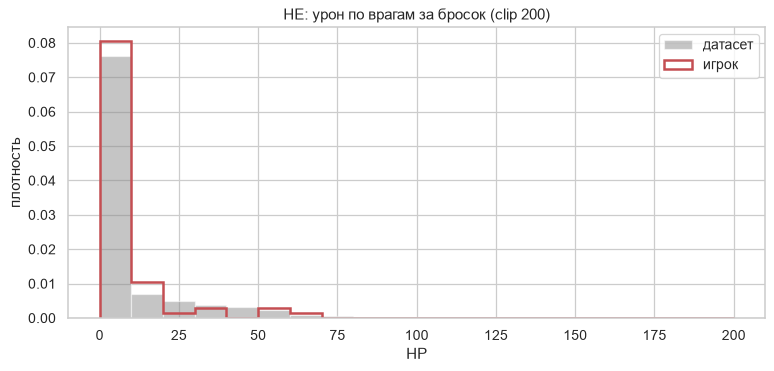

,игрок,команда,датасет
бросков,67.000,183.000,"565,392.000"
урон HP / бросок,5.910,10.481,8.729
урон броне / бросок,2.687,5.923,4.850
доля бросков с 0 урона,0.731,0.634,0.633
врагов задето / бросок,0.373,0.601,0.492
убийств на 100 бросков,0.000,4.372,2.390


In [9]:
def dmg_metrics(d):
    return pd.Series({
        'бросков': len(d),
        'урон HP / бросок': d['enemy_dmg'].mean(),
        'урон броне / бросок': d['enemy_armor_dmg'].mean(),
        'доля бросков с 0 урона': (d['enemy_dmg'] == 0).mean(),
        'врагов задето / бросок': d['n_enemies_hit'].mean(),
        'убийств на 100 бросков': 100 * d['enemy_kills'].mean(),
    })


he_all = throws[throws['grenade_type'] == 'he']
he_me = me[me['grenade_type'] == 'he']
he_tab = pd.DataFrame({
    'игрок': dmg_metrics(he_me),
    'команда': dmg_metrics(team_throws[team_throws['grenade_type'] == 'he']),
    'датасет': dmg_metrics(he_all),
})

fig, ax = plt.subplots(figsize=(10, 4.2))
bins = np.arange(0, 210, 10)
ax.hist(he_all['enemy_dmg'].clip(upper=200), bins=bins, density=True, color=CMP_COLORS['датасет'], alpha=0.5, label='датасет')
ax.hist(he_me['enemy_dmg'].clip(upper=200), bins=bins, density=True, histtype='step', lw=2, color=CMP_COLORS['игрок'], label='игрок')
ax.set_title('HE: урон по врагам за бросок (clip 200)'); ax.set_xlabel('HP'); ax.set_ylabel('плотность'); ax.legend()
plt.show()
he_tab

Самое слабое место игрока: **73% его HE не задевают ни одного врага** (датасет и тиммейты — 63%), средний урон 5.9 HP
за бросок против 8.7 по датасету и 10.5 у его тиммейтов, ни одного убийства с HE. Выборка — 67 гранат, поэтому ±10 п.п. по доле —
нормальный шум, но разрыв со всеми ориентирами в одну сторону.

**Оговорка:** HE с 0 урона — не обязательно плохой бросок. Это может быть промах, а может быть, что в зоне взрыва в этот момент
просто не было врагов (HE в проход «на всякий случай» или на звук, который не подтвердился). Отличить одно от другого нельзя:
позиции врагов в датасете есть только в момент урона или ослепления (раздел 2). Поэтому долю HE без урона читаем как сигнал
«стоит пересмотреть броски», а не как оценку каждого броска.

## 8. Анализ молотовов (Fire)

Те же метрики урона. **Оговорка:** молотов без урона — не обязательно ошибка. Часто его бросают, чтобы закрыть проход
или выкурить игрока с позиции (area denial), и успех — это когда враг *не пошёл* через огонь. Таких исходов в данных нет,
а площадь огня (`ConvexHull3D`) почти всегда пуста. Поэтому сравниваем с базой по стороне: у CT молотов чаще работает на задержку.

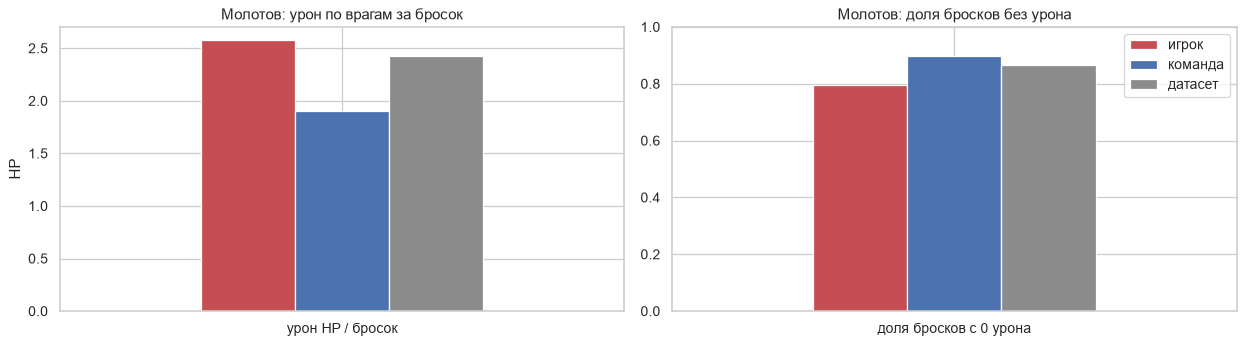

,игрок,команда,датасет
бросков,54.000,147.000,"446,164.000"
урон HP / бросок,2.574,1.905,2.428
урон броне / бросок,0.000,0.000,0.000
доля бросков с 0 урона,0.796,0.898,0.865
врагов задето / бросок,0.204,0.143,0.149
убийств на 100 бросков,0.000,0.680,0.933


бросков             урон HP / бросок         доля бросков с 0 урона        
       игрок     датасет            игрок датасет                  игрок датасет
side                                                                            
CT    31.000 258,574.000            1.774   1.939                  0.806   0.876
T     23.000 187,590.000            3.652   3.103                  0.783   0.850

In [10]:
mo_all = throws[throws['grenade_type'] == 'molotov']
mo_me = me[me['grenade_type'] == 'molotov']
mo_tab = pd.DataFrame({
    'игрок': dmg_metrics(mo_me),
    'команда': dmg_metrics(team_throws[team_throws['grenade_type'] == 'molotov']),
    'датасет': dmg_metrics(mo_all),
})
mo_side = pd.concat({
    'игрок': mo_me.groupby('side').apply(dmg_metrics, include_groups=False),
    'датасет': mo_all.groupby('side').apply(dmg_metrics, include_groups=False),
}).unstack(0)[['бросков', 'урон HP / бросок', 'доля бросков с 0 урона']]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
mo_tab.loc[['урон HP / бросок']].plot(kind='bar', color=CMP_COLORS, ax=axes[0], legend=False)
axes[0].set_title('Молотов: урон по врагам за бросок'); axes[0].set_ylabel('HP'); axes[0].tick_params(axis='x', rotation=0)
mo_tab.loc[['доля бросков с 0 урона']].plot(kind='bar', color=CMP_COLORS, ax=axes[1])
axes[1].set_title('Молотов: доля бросков без урона'); axes[1].set_ylim(0, 1); axes[1].tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()
display(mo_tab)
mo_side

По молотовам игрок **не хуже базы**: 2.6 HP за бросок против 2.4, без урона 80% против 87%. По сторонам картина та же
(T: 3.7 против 3.1 HP; CT: 1.8 против 1.9). Учитывая оговорку про area denial, здесь проблемы не видно.

## 9. Консистентность лайнапов (смоки)

**Идея.** Если смок бросается по заученному лайнапу, он каждый раз приземляется почти в одну точку.
Если «на глаз» — точки приземления разбросаны.

**Как считаем (прокси):**
1. **«Лайнап» = кластер DBSCAN по смокам самого игрока** (отдельно по сторонам) в пространстве
   (`tp_x`, `tp_y`, `to_x / 3`, `to_y / 3`). Точку приземления добавляем, чтобы отделить разные смоки, брошенные с одного места
   (у игрока, например, с (849, 301) и с (858, 255) — в 47 units друг от друга — летят смоки в точки, разнесённые на 330 units).
   Броски **других игроков** относим к лайнапу игрока, если ближайший бросок игрока из этого лайнапа — не дальше `eps` в том же пространстве.
   Берём только популярные лайнапы (≥ 30 бросков в датасете).
2. **Разброс** = расстояние (3D, units) между двумя приземлениями **одного и того же игрока** в одном лайнапе, по всем парам его бросков.
   Парное расстояние не зависит от того, сколько раз игрок бросил смок, поэтому игрока с 15 бросками можно сравнивать с игроками, у которых их 2–3.
3. Сравниваем разброс игрока с разбросом **других игроков в тех же лайнапах**: по каждому лайнапу берём медиану, потом усредняем
   с весом = число пар у игрока. Сравнивать «в среднем по всем смокам» нельзя: у лайнапов очень разный естественный разброс.

**Параметры DBSCAN** (`EPS = 50`, `MIN_SAMPLES = 2`, `TO_SCALE = 3`):
- `TO_SCALE = 3` — приземление «весит» в 3 раза меньше точки броска (та же пропорция, что у прежней сетки 100 / 300):
  у одного лайнапа точка приземления гуляет на десятки units, а разные цели с одного места разнесены на сотни.
- `EPS = 50` units. Игрок стоит на точке лайнапа с точностью до ~10–30 units, а бросок с разбега размазывает точку броска по пути:
  у T-смока игрока с (1197, 41) точки броска растянуты на 160 units с шагом до 41 unit. Расстояние до ближайшего соседнего броска игрока
  в этом пространстве заметно редеет около 46–54 units; при `EPS = 40` этот T-лайнап рвётся надвое, при 60 результат почти тот же, что при 50.
- `MIN_SAMPLES = 2` — лайнап можно оценить уже по паре бросков. **Одиночные броски DBSCAN помечает как шум (метка −1)**
  и в метрику они не идут: по одному броску консистентность не оценить.
- `tp_z` не используем: у соседних по (x, y) бросков |Δz| = 0 в медиане и ≤ 15 units в 95% случаев; заметная разница (~37 units) —
  только прыжок против броска с места, а она уже отражена в точке приземления. Высота в момент прыжка добавила бы только шум.

**Почему DBSCAN по смокам игрока, а не по всему датасету.** Точки броска в датасете очень плотные (медиана расстояния до 10-го соседа — 2.4 units):
игроки бросают смоки и на ходу по всему спавну. DBSCAN по всем 730k смокам «сцепляет» такие цепочки (проверяли, например, при `eps = 15`, `min_samples = 20`): CT-лайнап игрока с (−916, 1090)
попадает в кластер из ~94k бросков, где медианная точка броска в 181 units от его места. Если же кластеры строит только игрок, чужие броски
не могут растянуть кластер дальше `eps` от его собственных бросков.

**Ограничения прокси:** граница `eps` — тоже порог: бросок другого игрока чуть дальше 50 units не попадает в лайнап, а сильно промахнувшийся
смок (приземление дальше ~150 units от смоков игрока) выпадает из группы — значит, разброс по-прежнему может быть недооценён.
Если игрок сам бросает два близких лайнапа с промежуточных точек, DBSCAN может склеить их в один. Смок может отскочить или скатиться;
игрок может намеренно ставить смок в чуть разные места (например, one-way). Это сигнал «есть ли разброс», а не точная оценка техники.

In [11]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

EPS, MIN_SAMPLES, TO_SCALE, MIN_LINEUP_N = 50, 2, 3, 30
LINEUP_KEYS = ['side', 'lineup']

sm = throws.loc[throws['grenade_type'] == 'smoke', ['thrower_id', 'side', 'tp_x', 'tp_y', 'to_x', 'to_y', 'to_z']].copy()
sm['row'] = np.arange(len(sm))
sm['lineup'] = -1


def lineup_features(d):
    """Точка броска (x, y) + точка приземления (x, y), сжатая в TO_SCALE раз."""
    return np.column_stack([d['tp_x'], d['tp_y'], d['to_x'] / TO_SCALE, d['to_y'] / TO_SCALE])


# 1. DBSCAN по смокам игрока, отдельно по сторонам; метка -1 = одиночный бросок, в метрику не идёт
my_sm = sm[sm['thrower_id'] == PLAYER_ID]
for side, d in my_sm.groupby('side'):
    lab = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit_predict(lineup_features(d))
    sm.loc[d.index, 'lineup'] = np.where(lab >= 0, lab + sm['lineup'].max() + 1, -1)

# 2. броски других игроков -> в лайнап игрока, если ближайший его бросок этого лайнапа не дальше EPS
mine_cl = sm[(sm['thrower_id'] == PLAYER_ID) & (sm['lineup'] >= 0)]
for side, d in mine_cl.groupby('side'):
    o = sm[(sm['side'] == side) & (sm['thrower_id'] != PLAYER_ID)]
    dist, idx = NearestNeighbors(n_neighbors=1).fit(lineup_features(d)).kneighbors(lineup_features(o))
    sm.loc[o.index, 'lineup'] = np.where(dist[:, 0] <= EPS, d['lineup'].values[idx[:, 0]], -1)

sm['lineup_n'] = sm.groupby('lineup')['row'].transform('size')
rel = sm[(sm['lineup'] >= 0) & (sm['lineup_n'] >= MIN_LINEUP_N)]
n_my_smokes = len(my_sm)
print(f"Смоков у игрока: {n_my_smokes}, одиночных (DBSCAN, метка -1): {int((sm.loc[my_sm.index, 'lineup'] == -1).sum())}, "
      f"в популярных лайнапах: {(rel['thrower_id'] == PLAYER_ID).sum()}")

# все пары бросков одного игрока в одном лайнапе
pairs = rel.merge(rel, on=['thrower_id'] + LINEUP_KEYS, suffixes=('', '_b'))
pairs = pairs[pairs['row'] < pairs['row_b']]
pairs['spread'] = np.sqrt((pairs['to_x'] - pairs['to_x_b']) ** 2 + (pairs['to_y'] - pairs['to_y_b']) ** 2
                          + (pairs['to_z'] - pairs['to_z_b']) ** 2)
pairs['кто'] = np.where(pairs['thrower_id'] == PLAYER_ID, 'игрок', 'другие')
print('Макс. расстояние между точками броска в паре (units):',
      np.hypot(pairs['tp_x'] - pairs['tp_x_b'], pairs['tp_y'] - pairs['tp_y_b']).groupby(pairs['кто']).max().round(0).to_dict())

lineups = pairs.groupby(LINEUP_KEYS + ['кто'])['spread'].agg(['median', 'size']).unstack('кто').dropna()
lineups.columns = [f"{'разброс' if stat == 'median' else 'пар'}_{who}" for stat, who in lineups.columns]
lineups = lineups.join(rel[rel['thrower_id'] == PLAYER_ID].groupby(LINEUP_KEYS).agg(
    смоков_игрок=('row', 'size'), from_x=('tp_x', 'median'), from_y=('tp_y', 'median'), to_x=('to_x', 'median'), to_y=('to_y', 'median')))
lineups = lineups.sort_values('смоков_игрок', ascending=False)

w = lineups['пар_игрок']
SMOKE_SPREAD_ME = np.average(lineups['разброс_игрок'], weights=w)
SMOKE_SPREAD_BASE = np.average(lineups['разброс_другие'], weights=w)
print(f'Лайнапов, которые игрок бросил ≥ 2 раз: {len(lineups)}, смоков в них: {lineups["смоков_игрок"].sum()}')
print(f'Разброс приземления (взвеш.): игрок {SMOKE_SPREAD_ME:.0f} units, другие игроки в тех же лайнапах {SMOKE_SPREAD_BASE:.0f} units')
print(f"Лайнапов, где игрок точнее других: {(lineups['разброс_игрок'] < lineups['разброс_другие']).sum()} из {len(lineups)}")
lineups.reset_index()[['side', 'смоков_игрок', 'from_x', 'from_y', 'to_x', 'to_y', 'разброс_игрок', 'разброс_другие', 'пар_другие']].round(0)

Смоков у игрока: 84, одиночных (DBSCAN, метка -1): 39, в популярных лайнапах: 45
Макс. расстояние между точками броска в паре (units): {'другие': 175.0, 'игрок': 182.0}
Лайнапов, которые игрок бросил ≥ 2 раз: 6, смоков в них: 45
Разброс приземления (взвеш.): игрок 43 units, другие игроки в тех же лайнапах 37 units
Лайнапов, где игрок точнее других: 1 из 6


,side,смоков_игрок,from_x,from_y,to_x,to_y,разброс_игрок,разброс_другие,пар_другие
0,CT,18,-916.000,"1,090.000",495.000,"1,709.000",14.000,12.000,43483
1,T,16,"1,197.000",41.000,590.000,363.000,77.000,68.000,139
2,CT,4,-418.000,15.000,"1,021.000",323.000,87.000,53.000,54801
3,T,3,858.000,255.000,-173.000,0.000,127.000,61.000,12
4,CT,2,-227.000,418.000,"1,098.000",204.000,39.000,37.000,158
5,T,2,"2,917.000",69.000,822.000,237.000,44.000,45.000,4


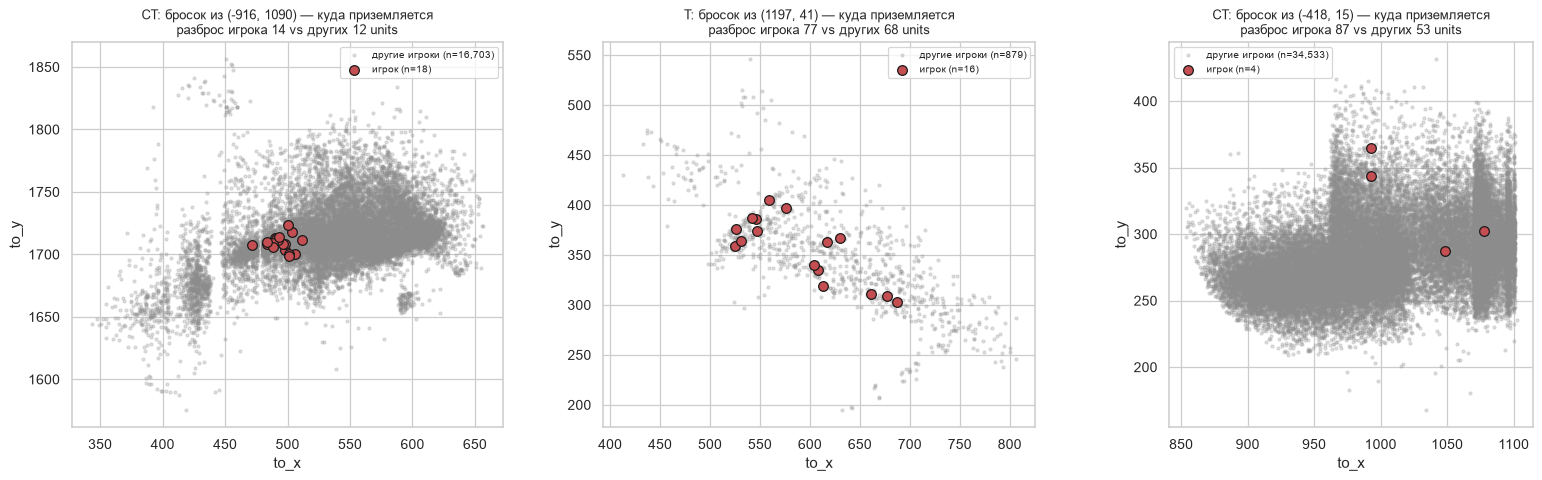

In [12]:
top = lineups.head(3)
fig, axes = plt.subplots(1, len(top), figsize=(6 * len(top), 5.5))
for ax, (key, row) in zip(np.atleast_1d(axes), top.iterrows()):
    lp = rel.set_index(LINEUP_KEYS).loc[[key]]
    o, m = lp[lp['thrower_id'] != PLAYER_ID], lp[lp['thrower_id'] == PLAYER_ID]
    ax.scatter(o['to_x'], o['to_y'], s=6, alpha=0.25, color=CMP_COLORS['датасет'], label=f'другие игроки (n={len(o):,})')
    ax.scatter(m['to_x'], m['to_y'], s=60, color=CMP_COLORS['игрок'], edgecolor='k', label=f'игрок (n={len(m)})')
    ax.set_aspect('equal'); ax.legend(fontsize=8)
    ax.set_title(f"{key[0]}: бросок из ({row['from_x']:.0f}, {row['from_y']:.0f}) — куда приземляется\n"
                 f"разброс игрока {row['разброс_игрок']:.0f} vs других {row['разброс_другие']:.0f} units", fontsize=10)
    ax.set_xlabel('to_x'); ax.set_ylabel('to_y')
plt.tight_layout(); plt.show()

- Из 84 смоков игрока DBSCAN собрал **45 в 6 лайнапов** (все популярные, ≥ 30 бросков в датасете); **39 — одиночные броски** (метка −1),
  в метрику они не идут. У прежней сетки было 11 лайнапов с ≥ 2 бросками и 44 смока: смоков столько же, но DBSCAN не дробит один лайнап по соседним клеткам.
- **Взвешенный разброс — 43 units против 37 у других игроков** в тех же лайнапах (×1.16): чуть хуже, но ниже порога «проблемы» (×1.25) из раздела 12.
  При сетке было 21 против 22. Разница — в основном из-за T-лайнапа с (1197, 41): теперь он собран целиком (16 бросков, 120 пар) и весит больше,
  а разброс в нём 77 против 68 — это бросок с разбега, точка броска растянута на 160 units.
- Основной CT-смок из (−916, 1090), брошенный 18 раз: **14 против 12 units** — это заученный лайнап (при сетке 13 против 11).
- В лайнапах с 2–4 бросками разброс выше, чем у других: CT из (−418, 15) — 87 против 53, T из (858, 255) — 127 против 61.
  На 2–4 бросках это кандидаты на пересмотр, а не вывод. В CT-лайнапе из (−418, 15) приземления игрока делятся на две группы
  (to ≈ (1050–1080, 290–300) и (993, 345–365)) — возможно, это два разных смока, которые DBSCAN склеил (см. ограничения выше).
- **Артефакт сетки ушёл:** раньше облако приземлений T-лайнапа обрезалось по `to_x = 600` (граница клетки 300×300), теперь на среднем графике
  оно непрерывно от ~520 до ~690. Похожая граница осталась в другой форме: облако «других игроков» ограничено радиусом `eps` вокруг бросков игрока
  (на правом графике левый край облака около `to_x ≈ 850` — это ~150 units от его крайнего смока), то есть дальние промахи других игроков
  в сравнение по-прежнему не попадают.

## 10. Тайминг бросков по раунду

`t_in_round` — секунды от первой гранаты раунда (любого игрока) до броска. Это не настоящее время с начала раунда
(тика окончания freeze time в данных нет), но для сравнения «игрок vs все» в одних и тех же условиях прокси годится.

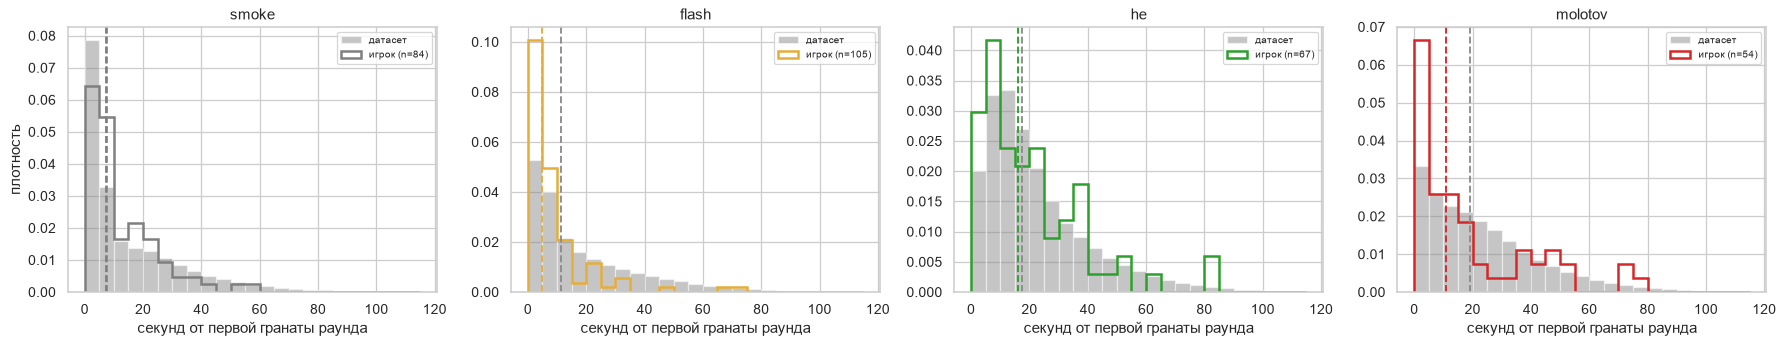

игрок                         датасет                        
                  медиана доля < 20 с доля > 60 с медиана доля < 20 с доля > 60 с
grenade_type side                                                                
smoke        CT     6.336       0.947       0.000   5.547       0.825       0.019
             T     14.094       0.652       0.000  15.906       0.573       0.046
flash        CT     8.719       0.800       0.025  16.016       0.573       0.063
             T      3.375       0.923       0.015   8.281       0.704       0.040
he           CT     8.844       0.771       0.057  14.672       0.633       0.042
             T     24.859       0.375       0.031  21.094       0.471       0.059
molotov      CT     4.250       0.903       0.032  12.297       0.632       0.051
             T     25.641       0.391       0.087  25.578       0.356       0.079

In [13]:
T_MAX = 115
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, gt in zip(axes, GT_ORDER):
    base = throws.loc[throws['grenade_type'] == gt, 't_in_round'].clip(upper=T_MAX)
    mine = me.loc[me['grenade_type'] == gt, 't_in_round'].clip(upper=T_MAX)
    bins = np.arange(0, T_MAX + 5, 5)
    ax.hist(base, bins=bins, density=True, color=CMP_COLORS['датасет'], alpha=0.5, label='датасет')
    ax.hist(mine, bins=bins, density=True, histtype='step', lw=2, color=GT_COLORS[gt], label=f'игрок (n={len(mine)})')
    ax.axvline(base.median(), color=CMP_COLORS['датасет'], ls='--'); ax.axvline(mine.median(), color=GT_COLORS[gt], ls='--')
    ax.set_title(gt); ax.set_xlabel('секунд от первой гранаты раунда'); ax.legend(fontsize=8)
axes[0].set_ylabel('плотность')
plt.tight_layout(); plt.show()


def timing(d):
    return d.groupby(['grenade_type', 'side'])['t_in_round'].agg(
        медиана='median', **{'доля < 20 с': lambda s: (s < 20).mean(), 'доля > 60 с': lambda s: (s > 60).mean()})


timing_tab = pd.concat({'игрок': timing(me), 'датасет': timing(throws)}, axis=1).reindex(GT_ORDER, level=0)
timing_tab

- Игрок бросает утилити **заметно раньше** базы: на CT медиана флешки — 8.7 с против 16.0, молотова — 4.3 с против 12.3,
  90% молотовов на CT уходят в первые 20 с (по датасету 63%). На T флешки тоже ранние (медиана 3.4 с против 8.3).
- HE на T, наоборот, чуть позже базы (24.9 с против 21.1).
- Без экономики и результатов раундов нельзя сказать, хорошо это или плохо: ранняя утилити на CT — нормальная защита,
  но может значить, что к поздней фазе раунда гранат уже нет.

## 11. Связь метрик утилити с PremierRatingNew

Берём всех игроков с известным рейтингом (средний рейтинг по их матчам), считаем ключевые метрики по всем их броскам
и делим игроков на 5 квантильных бакетов по рейтингу. Метрику игрока учитываем, только если у него ≥ 5 гранат этого типа —
иначе одна флешка даёт 0% или 100%.

Затем смотрим, где выбранный игрок находится **внутри своего бакета** (перцентиль: какая доля игроков бакета имеет значение ниже).

**Оговорка:** это корреляция, а не причинность. Высокий рейтинг связан и с опытом, и с аимом, и с командной игрой;
утилити — только одна из составляющих. Кроме того, у большинства игроков в бакете всего один матч, а у нашего — несколько,
поэтому его метрики менее шумные, чем у соседей.

In [14]:
MIN_TYPE_N = 5
rating_pp = players.dropna(subset=['rating']).groupby('player_id')['rating'].mean()
thr_r = throws[throws['thrower_id'].isin(rating_pp.index)].copy()
thr_r['zero_dmg'] = thr_r['enemy_dmg'] == 0
thr_r['empty_flash'] = thr_r['n_flashed_enemy'] == 0
thr_r['early20'] = thr_r['t_in_round'] < 20


def per_player_metric(gt, col):
    g = thr_r[thr_r['grenade_type'] == gt].groupby('thrower_id')[col].agg(['mean', 'size'])
    return g.loc[g['size'] >= MIN_TYPE_N, 'mean']


def per_player_metric_all(col, min_n=MIN_TYPE_N):
    """Как per_player_metric, но по всем броскам игрока, без фильтра по типу гранаты."""
    g = thr_r.groupby('thrower_id')[col].agg(['mean', 'size'])
    return g.loc[g['size'] >= min_n, 'mean']


player_rounds = (throws[['match_id', 'thrower_id']].drop_duplicates()
                 .assign(r=lambda d: rounds_in_match.reindex(d['match_id']).values).groupby('thrower_id')['r'].sum())
METRICS = {
    'гранат за раунд': thr_r.groupby('thrower_id').size() / player_rounds,
    'флешка: врагов ослеплено': per_player_metric('flash', 'n_flashed_enemy'),
    'флешка: своих ослеплено': per_player_metric('flash', 'n_flashed_own'),
    'флешка: доля без врагов': per_player_metric('flash', 'empty_flash'),
    'HE: урон / бросок': per_player_metric('he', 'enemy_dmg'),
    'HE: доля с 0 урона': per_player_metric('he', 'zero_dmg'),
    'молотов: урон / бросок': per_player_metric('molotov', 'enemy_dmg'),
    'молотов: доля с 0 урона': per_player_metric('molotov', 'zero_dmg'),
    'flash-kill на 100 флешек': 100 * per_player_metric('flash', 'flash_kills'),
    'доля ранней утилити (<20 с от 1-й гранаты раунда)': per_player_metric_all('early20'),
}
pr = pd.DataFrame(METRICS).join(rating_pp.rename('rating'), how='inner')
pr['bucket'] = pd.qcut(pr['rating'], 5)
bucket_tab = pr.groupby('bucket', observed=True)[list(METRICS)].mean()
bucket_tab['игроков'] = pr.groupby('bucket', observed=True).size()
bucket_tab.index = [f'{int(iv.left):,}–{int(iv.right):,}' for iv in bucket_tab.index]

my_bucket = pr.loc[PLAYER_ID, 'bucket']
peers = pr[pr['bucket'] == my_bucket]
my_pos = pd.DataFrame({
    'игрок': pr.loc[PLAYER_ID, list(METRICS)],
    'среднее бакета': peers[list(METRICS)].mean(),
    'перцентиль в бакете': [(peers[m].dropna() < pr.loc[PLAYER_ID, m]).mean() for m in METRICS],
})
MY_BUCKET_LABEL = f'{int(my_bucket.left):,}–{int(my_bucket.right):,}'
print(f'Игрок {PLAYER_ID}: рейтинг {MY_RATING:,.0f}, бакет {MY_BUCKET_LABEL}, игроков в бакете: {len(peers):,}')
display(bucket_tab)
my_pos

Игрок 441472604: рейтинг 16,568, бакет 16,332–19,959, игроков в бакете: 4,233


,гранат за раунд,флешка: врагов ослеплено,флешка: своих ослеплено,флешка: доля без врагов,HE: урон / бросок,HE: доля с 0 урона,молотов: урон / бросок,молотов: доля с 0 урона,flash-kill на 100 флешек,доля ранней утилити (<20 с от 1-й гранаты раунда),игроков
"999–8,506",0.986,0.711,0.822,0.510,7.979,0.664,2.392,0.875,4.169,0.621,4237
"8,506–12,978",1.130,0.721,0.792,0.503,8.304,0.645,2.276,0.871,4.286,0.611,4229
"12,978–16,332",1.210,0.747,0.771,0.484,8.925,0.631,2.385,0.867,4.393,0.612,4233
"16,332–19,959",1.294,0.769,0.772,0.473,8.975,0.625,2.425,0.864,4.879,0.610,4233
"19,959–30,120",1.384,0.801,0.807,0.454,9.390,0.610,2.562,0.856,5.750,0.629,4233


,игрок,среднее бакета,перцентиль в бакете
гранат за раунд,1.802,1.294,0.791
флешка: врагов ослеплено,0.886,0.769,0.674
флешка: своих ослеплено,0.952,0.772,0.699
флешка: доля без врагов,0.486,0.473,0.505
HE: урон / бросок,5.910,8.975,0.373
HE: доля с 0 урона,0.731,0.625,0.726
молотов: урон / бросок,2.574,2.425,0.665
молотов: доля с 0 урона,0.796,0.864,0.216
flash-kill на 100 флешек,1.905,4.879,0.601
доля ранней утилити (<20 с от 1-й гранаты раунда),0.755,0.610,0.795


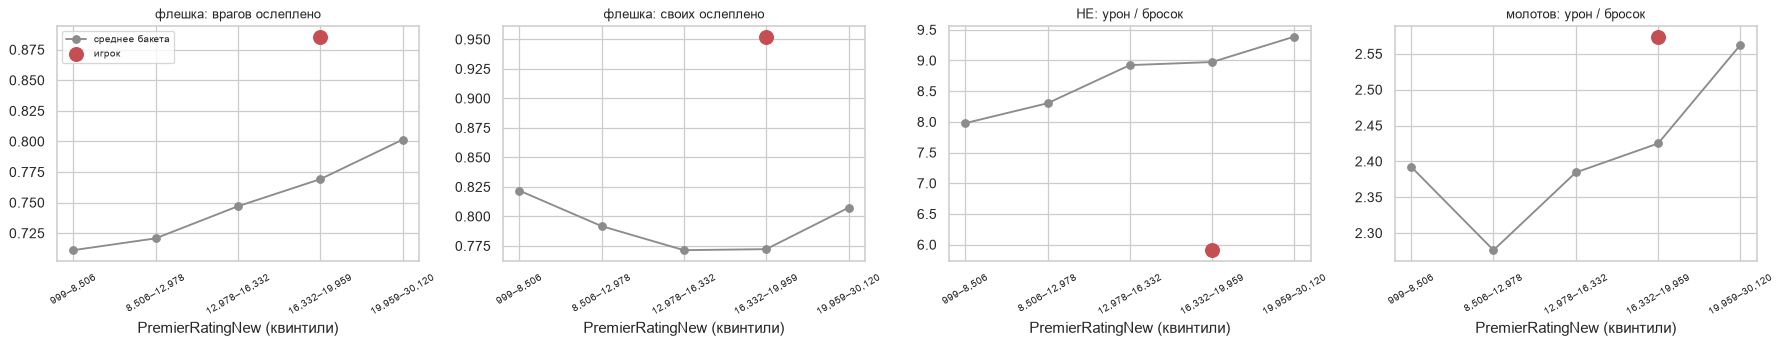

In [15]:
show = ['флешка: врагов ослеплено', 'флешка: своих ослеплено', 'HE: урон / бросок', 'молотов: урон / бросок']
my_i = list(bucket_tab.index).index(MY_BUCKET_LABEL)
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, m in zip(axes, show):
    ax.plot(bucket_tab.index, bucket_tab[m], marker='o', color=CMP_COLORS['датасет'], label='среднее бакета')
    ax.scatter([my_i], [pr.loc[PLAYER_ID, m]], s=120, color=CMP_COLORS['игрок'], zorder=3, label='игрок')
    ax.set_title(m, fontsize=10); ax.set_xlabel('PremierRatingNew (квинтили)'); ax.tick_params(axis='x', rotation=30, labelsize=8)
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

- По всему датасету с ростом рейтинга монотонно растут число гранат за раунд, число ослеплённых врагов на флешку и урон HE,
  а доля пустых флешек и HE без урона падает. Ослепление своих почти не зависит от тира (0.77–0.82).
- Игрок (рейтинг ~16.6k) попадает в бакет 16 332–19 959 (4 233 игрока). Внутри бакета:
  - **сильнее большинства** по количеству утилити (79-й перцентиль), ослеплённым врагам (67-й) и доле молотовов с уроном;
  - **слабее большинства** по своим ослеплённым на флешку (хуже 70% тира) и по доле HE без урона (хуже 73%);
    по урону HE за бросок (5.9 HP) он ниже среднего **любого** бакета, включая самый низкий (8.0).
- Напоминание: это корреляция. Улучшив HE, игрок не получит автоматически +N рейтинга; но это то, чем игроки выше по рейтингу в среднем отличаются.

## 12. Выводы для игрока

Рекомендации ниже собираются автоматически из цифр, посчитанных выше. Главный ориентир — игроки его тира (раздел 11).
Чтобы не реагировать на шум маленькой выборки, метрику считаем **проблемой**, только если игрок хуже 2/3 игроков своего тира
(перцентиль ≥ 67% для «плохих» метрик и ≤ 33% для «хороших»), и **сильной стороной** — если лучше 2/3 тира.
Для смоков порог — разброс на 25% больше, чем у других игроков в тех же лайнапах.

Каждой проблеме сопоставлен инструмент SCOPE.GG из `docs/scope_gg_products_research.md`:
- **Grenade Predictor** (https://scope.gg/grenade-predictor) — лайнапы smoke/flash/HE/molotov на 2D-карте, видео-гайды, `setpos`-координаты, версии под 64/128 tick;
- **CS2 Dashboard → My Progress** (app.scope.gg) — тренд метрик, включая утилити, за последние 30 матчей;
- **Demo Viewer** — 2D-повтор матча и performance review (разбор ошибок по карте);
- **Comparing tool** — сравнение статистики с другим игроком.

In [16]:
BAD_PCT = 2 / 3
pct, peer, mine = my_pos['перцентиль в бакете'], my_pos['среднее бакета'], my_pos['игрок']
n_fl, n_he, n_mo = int(fl_tab.loc['флешек', 'игрок']), int(he_tab.loc['бросков', 'игрок']), int(mo_tab.loc['бросков', 'игрок'])
recs, strengths = [], []

if pct['гранат за раунд'] >= BAD_PCT:
    strengths.append(f"ты бросаешь много утилити: {mine['гранат за раунд']:.2f} гранаты за раунд против {peer['гранат за раунд']:.2f} в тире")

# флешки: ослепление своих (чем меньше, тем лучше)
if pct['флешка: своих ослеплено'] >= BAD_PCT:
    recs.append(
        f"**Флешки слепят своих.** На одну флешку ты ослепляешь {mine['флешка: своих ослеплено']:.2f} своих (тиммейтов и себя), "
        f"в твоём тире — {peer['флешка: своих ослеплено']:.2f} (хуже, чем у {pct['флешка: своих ослеплено']:.0%} игроков тира). "
        f"Разбери в **Demo Viewer** раунды, где ты слепил своих, "
        f"и замени эти броски на поп-флешки из **Grenade Predictor**, которые взрываются над врагом, а не перед тиммейтом. (посчитано по твоим {n_fl} флешкам)")

# флешки: ослепление врагов и пустые флешки
if pct['флешка: врагов ослеплено'] >= BAD_PCT:
    strengths.append(f"флешки слепят больше врагов, чем у {pct['флешка: врагов ослеплено']:.0%} игроков тира "
                     f"({mine['флешка: врагов ослеплено']:.2f} против {peer['флешка: врагов ослеплено']:.2f} на флешку)")
if pct['флешка: доля без врагов'] >= BAD_PCT:
    recs.append(
        f"**{mine['флешка: доля без врагов']:.0%} твоих флешек не ослепляют ни одного врага** (в тире {peer['флешка: доля без врагов']:.0%}). "
        "Возьми из **Grenade Predictor** 2–3 флеш-лайнапа на Cache под свою роль и отработай их по `setpos`; "
        "в **Demo Viewer** проверь, где стояли враги в момент пустых флешек.")

# флешки: конверсия в убийства — сравнение с тиром (не с датасетом)
if pct['flash-kill на 100 флешек'] <= 1 - BAD_PCT:
    recs.append(
        f"**Ослеплённых врагов почти не добивают.** {mine['flash-kill на 100 флешек']:.1f} flash-kill на 100 флешек "
        f"против {peer['flash-kill на 100 флешек']:.1f} в твоём тире. "
        "Флешки слепят врагов, но редко превращаются в убийства. Посмотри в **Demo Viewer**, был ли рядом тиммейт, готовый пикнуть "
        "сразу после взрыва, и договаривайся о таком заходе заранее. Оговорка: это редкие события на малой выборке, разница может быть случайной.")

# HE
if pct['HE: доля с 0 урона'] >= BAD_PCT or pct['HE: урон / бросок'] <= 1 - BAD_PCT:
    recs.append(
        f"**{mine['HE: доля с 0 урона']:.0%} твоих HE наносят 0 урона** (в твоём тире {peer['HE: доля с 0 урона']:.0%}), "
        f"в среднем {mine['HE: урон / бросок']:.1f} HP за бросок против {peer['HE: урон / бросок']:.1f}. "
        f"Попробуй стандартные HE-лайнапы из **Grenade Predictor** на частые позиции врагов вместо бросков «на звук». (посчитано по твоим {n_he} HE-броскам)")
elif pct['HE: урон / бросок'] >= BAD_PCT:
    strengths.append(f"HE: {mine['HE: урон / бросок']:.1f} HP за бросок против {peer['HE: урон / бросок']:.1f} в тире")

# молотовы
if pct['молотов: урон / бросок'] <= 1 - BAD_PCT:
    recs.append(
        f"**Молотовы:** {mine['молотов: доля с 0 урона']:.0%} без урона (в тире {peer['молотов: доля с 0 урона']:.0%}), "
        f"{mine['молотов: урон / бросок']:.1f} HP за бросок против {peer['молотов: урон / бросок']:.1f}. Часть таких молотовов могла честно "
        "закрыть проход, поэтому сначала проверь в **Demo Viewer**, отступил ли враг; если нет — возьми молотов-лайнапы из **Grenade Predictor**.")
elif pct['молотов: доля с 0 урона'] <= 1 - BAD_PCT:
    strengths.append(f"молотовы чаще тира задевают врага: без урона {mine['молотов: доля с 0 урона']:.0%} против {peer['молотов: доля с 0 урона']:.0%}")

# смоки
if SMOKE_SPREAD_ME > 1.25 * SMOKE_SPREAD_BASE:
    recs.append(
        f"**Смоки ложатся неточно.** В повторяющихся лайнапах два твоих смока в среднем приземляются в {SMOKE_SPREAD_ME:.0f} units друг от друга, "
        f"у других игроков в тех же лайнапах — в {SMOKE_SPREAD_BASE:.0f}. Похоже на броски на глаз: выучи эти смоки по **Grenade Predictor** "
        "(видео + `setpos`, версия под 64 или 128 tick).")
elif SMOKE_SPREAD_ME <= 1.1 * SMOKE_SPREAD_BASE:
    strengths.append(f"смоки в повторяющихся лайнапах ложатся на уровне других игроков: разброс {SMOKE_SPREAD_ME:.0f} units против {SMOKE_SPREAD_BASE:.0f}")

# тайминг: заметно более ранняя утилити, чем в тире (не датасет) — это стиль, не ошибка:
# тайминг почти не различает тиры (раздел 11 и docs/poc_findings_summary.md), поэтому не выносим как "проблему"
early_me, early_peer = mine['доля ранней утилити (<20 с от 1-й гранаты раунда)'], peer['доля ранней утилити (<20 с от 1-й гранаты раунда)']
if abs(early_me - early_peer) > 0.2:
    recs.append(
        f"**Ранняя утилити** (это особенность стиля, не ошибка — по тайминг-метрикам тиры почти не различаются). "
        f"{early_me:.0%} твоих гранат уходят в первые 20 секунд после первой гранаты раунда (это прокси начала раунда — "
        f"точного времени старта раунда в данных нет), в твоём тире — {early_peer:.0%}. Раннее использование может быть стандартной "
        "защитой, а может оставлять тебя без гранат к ретейку или поздней фазе раунда — экономики и исходов раундов в данных нет. "
        "Проверь в **Demo Viewer**, на что ушли ранние гранаты и чего не хватило в конце раунда.")

# всегда: трекинг и сравнение
recs.append(
    "**Отслеживай прогресс.** Метрики выше посчитаны по нескольким матчам — этого мало для окончательного вывода. "
    "Смотри их тренд в **CS2 Dashboard → My Progress** (последние 30 матчей): доля HE без урона, своих ослеплённых на флешку.")
recs.append(
    "**Сравни себя с сильным тиммейтом.** Через **Comparing tool** сравни утилити-статистику с игроком из своего стака, "
    "у которого меньше ослеплённых своих и больше урона с HE.")

text = '**Что улучшить:**\n\n' + '\n'.join(f'{i}. {r}' for i, r in enumerate(recs, 1))
if strengths:
    text += '\n\n**Что уже хорошо:** ' + '; '.join(strengths) + '.'
display(Markdown(text))

**Что улучшить:**

1. **Флешки слепят своих.** На одну флешку ты ослепляешь 0.95 своих (тиммейтов и себя), в твоём тире — 0.77 (хуже, чем у 70% игроков тира). Разбери в **Demo Viewer** раунды, где ты слепил своих, и замени эти броски на поп-флешки из **Grenade Predictor**, которые взрываются над врагом, а не перед тиммейтом. (посчитано по твоим 105 флешкам)
2. **73% твоих HE наносят 0 урона** (в твоём тире 62%), в среднем 5.9 HP за бросок против 9.0. Попробуй стандартные HE-лайнапы из **Grenade Predictor** на частые позиции врагов вместо бросков «на звук». (посчитано по твоим 67 HE-броскам)
3. **Отслеживай прогресс.** Метрики выше посчитаны по нескольким матчам — этого мало для окончательного вывода. Смотри их тренд в **CS2 Dashboard → My Progress** (последние 30 матчей): доля HE без урона, своих ослеплённых на флешку.
4. **Сравни себя с сильным тиммейтом.** Через **Comparing tool** сравни утилити-статистику с игроком из своего стака, у которого меньше ослеплённых своих и больше урона с HE.

**Что уже хорошо:** ты бросаешь много утилити: 1.80 гранаты за раунд против 1.29 в тире; флешки слепят больше врагов, чем у 67% игроков тира (0.89 против 0.77 на флешку); молотовы чаще тира задевают врага: без урона 80% против 86%.

### Итог

Для игрока `441472604` (9 матчей, 310 гранат, рейтинг ~16.6k) главные точки роста по утилити:
1. **HE-гранаты** — почти три четверти без урона и урон за бросок ниже любого тира. Самая конкретная и легко тренируемая проблема → Grenade Predictor.
2. **Флешки в своих** — ослепляет тиммейтов чаще 70% игроков своего тира → Demo Viewer + поп-флешки из Grenade Predictor.

По проценту в своём тире конверсия флешек в киллы (60-й перцентиль) и доля ранней утилити (разница с тиром 14.5 п.п., ниже порога 20 п.п.)
не выделяются — это не точки роста, раздел 11 их не флагует.

Сильные стороны: много утилити, флешки слепят врагов лучше тира, стабильный основной CT-смок, молотовы не хуже базы.
Смоки в целом — на уровне других игроков в тех же лайнапах (разброс ×1.16, ниже порога проблемы).

**Что не позволило докрутить концепт** (см. раздел 2): у одного игрока в датасете максимум ~10 матчей, поэтому по каждому типу гранат —
десятки бросков и широкие доверительные интервалы; нет стрельбы, движения, экономики, смертей не от гранат и исходов раундов,
нет начала раунда и исхода смоков; урон HE/огня по своим не записан. В продукте эти же метрики стоит считать по всей истории
игрока (30+ матчей, как в My Progress) и по его реальным демкам.